In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
phq8_unfiltered = pd.read_csv("data_cleaned/phq8_data.csv")

In [3]:
phq8_unfiltered.columns

Index(['participant_name', 'timeInterval_ID', 'phq8_score'], dtype='str')

In [18]:
def plot_phq8_distribution(phq8, title):
    """
    Plot the distribution of PHQ-8 scores.

    Parameters
    ----------
    phq8 : pandas.Series
        PHQ-8 scores (0-24).
    title : str
        Plot title.
    """
    phq8 = phq8.dropna()

    plt.figure(figsize=(8, 5))

    bins = [-0.5, 4.5, 9.5, 14.5, 19.5, 24.5]
    labels = [
        "None\n(0–4)",
        "Mild\n(5–9)",
        "Moderate\n(10–14)",
        "Mod. Severe\n(15–19)",
        "Severe\n(20–24)"
    ]

    cats = pd.cut(phq8, bins=bins, labels=labels)

    counts = cats.value_counts(sort=False)

    ax = counts.plot.bar(edgecolor="black")

    # Add count labels above bars
    for i, count in enumerate(counts):
        ax.text(
            i,
            count,
            str(count),
            ha="center",
            va="bottom",
            fontsize=10
        )

    plt.xlabel("PHQ-8 Severity")
    plt.ylabel("Count")
    plt.title(title)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

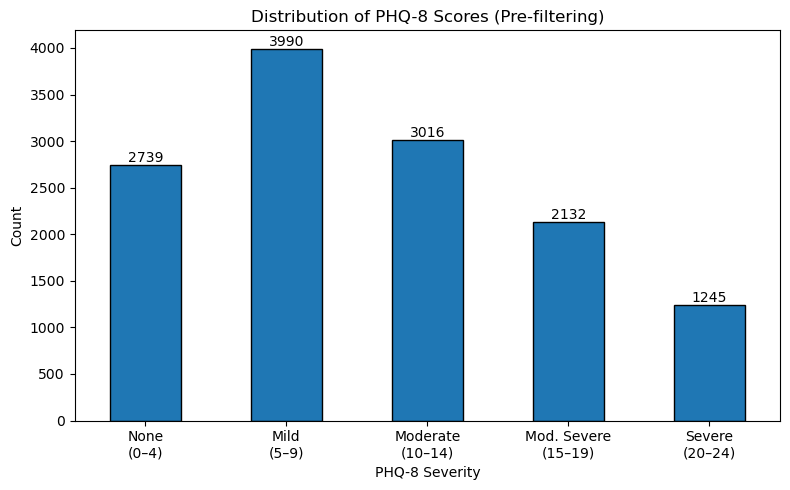

In [19]:
plot_phq8_distribution(phq8_unfiltered["phq8_score"], "Distribution of PHQ-8 Scores (Pre-filtering)")

In [ ]:
w3_merged = pd.read_parquet("data_merged/final_dataset_w3_mp0.8_noc22.parquet")

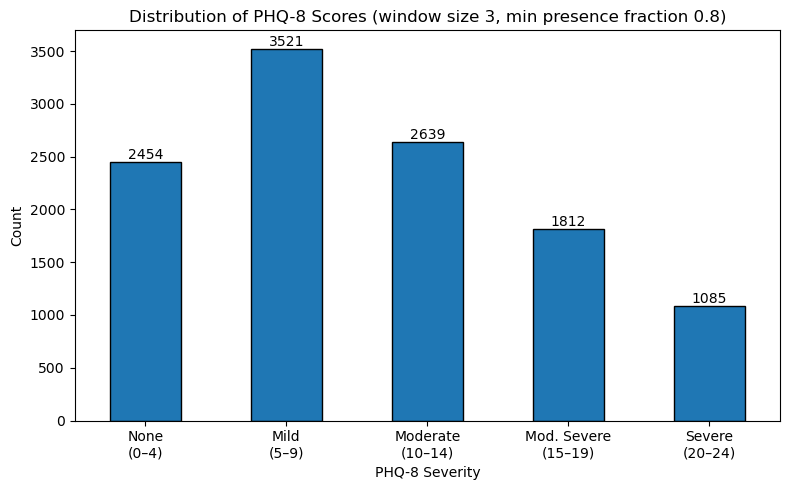

In [22]:
plot_phq8_distribution(w3_merged["phq8_score"], "Distribution of PHQ-8 Scores (window size 3, min presence fraction 0.8)")

In [23]:
w7_merged = pd.read_parquet("data_merged/final_dataset_w7_mp0.8_noc22.parquet")

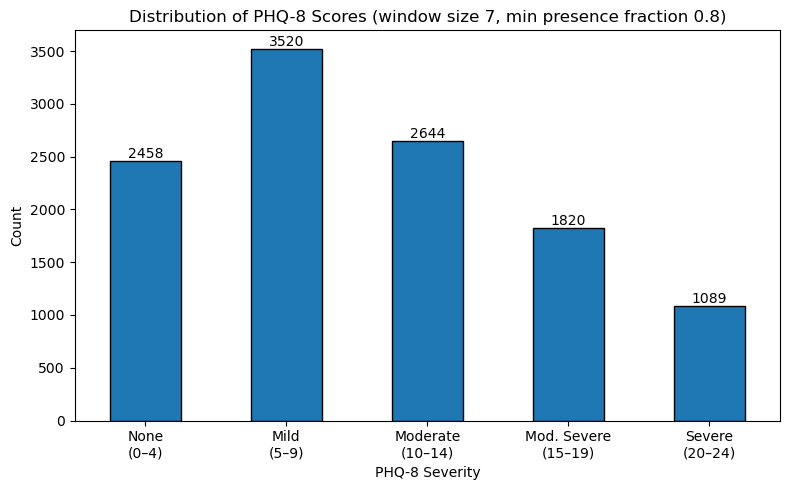

In [24]:
plot_phq8_distribution(w7_merged["phq8_score"], "Distribution of PHQ-8 Scores (window size 7, min presence fraction 0.8)")

In [29]:
w14_merged = pd.read_parquet("data_merged/final_dataset_w14_mp0.8_c22.parquet")

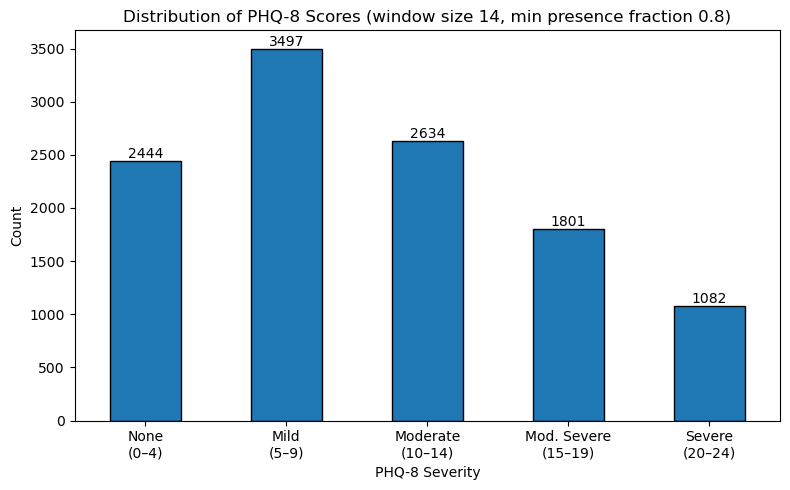

In [30]:
plot_phq8_distribution(w14_merged["phq8_score"], "Distribution of PHQ-8 Scores (window size 14, min presence fraction 0.8)")

In [31]:
w28_merged = pd.read_parquet("data_merged/final_dataset_w28_mp0.8_c22.parquet")

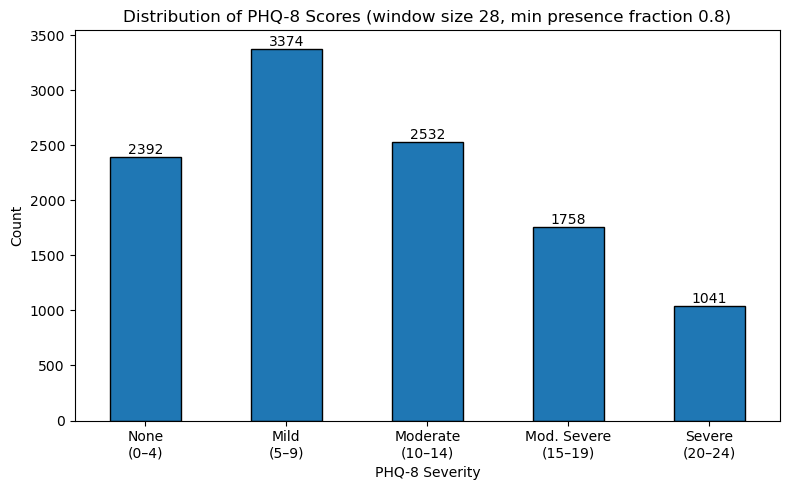

In [32]:
plot_phq8_distribution(w28_merged["phq8_score"], "Distribution of PHQ-8 Scores (window size 28, min presence fraction 0.8)")

In [33]:
def phq8_severity_counts(phq8):
    """Return exact per-band PHQ-8 counts using the same bins as the plots."""
    bins = [-0.5, 4.5, 9.5, 14.5, 19.5, 24.5]
    labels = [
        "None (0-4)",
        "Mild (5-9)",
        "Moderate (10-14)",
        "Mod. Severe (15-19)",
        "Severe (20-24)",
    ]
    cats = pd.cut(phq8.dropna(), bins=bins, labels=labels)
    return cats.value_counts(sort=False)


datasets = {
    "Pre-filter": phq8_unfiltered["phq8_score"],
    "w3": w3_merged["phq8_score"],
    "w7": w7_merged["phq8_score"],
    "w14": w14_merged["phq8_score"],
    "w28": w28_merged["phq8_score"],
}

# Exact value_counts per severity band
counts = pd.DataFrame({name: phq8_severity_counts(s) for name, s in datasets.items()})
counts.loc["Total"] = counts.sum()
print("Exact PHQ-8 severity counts")
print(counts.to_string())

# Proportions within each dataset (excludes the Total row)
proportions = counts.drop(index="Total")
proportions = (proportions / proportions.sum()).mul(100).round(2)
print("\nProportion within dataset (%)")
print(proportions.to_string())

# Retention vs. pre-filter, per band and overall
base = counts["Pre-filter"]
retention = counts.drop(columns="Pre-filter").div(base, axis=0).mul(100).round(1)
print("\nRetention vs. pre-filter (%)")
print(retention.to_string())


Exact PHQ-8 severity counts
                     Pre-filter     w3     w7    w14    w28
phq8_score                                                 
None (0-4)                 2739   2454   2458   2444   2392
Mild (5-9)                 3990   3521   3520   3497   3374
Moderate (10-14)           3016   2639   2644   2634   2532
Mod. Severe (15-19)        2132   1812   1820   1801   1758
Severe (20-24)             1245   1085   1089   1082   1041
Total                     13122  11511  11531  11458  11097

Proportion within dataset (%)
                     Pre-filter     w3     w7    w14    w28
phq8_score                                                 
None (0-4)                20.87  21.32  21.32  21.33  21.56
Mild (5-9)                30.41  30.59  30.53  30.52  30.40
Moderate (10-14)          22.98  22.93  22.93  22.99  22.82
Mod. Severe (15-19)       16.25  15.74  15.78  15.72  15.84
Severe (20-24)             9.49   9.43   9.44   9.44   9.38

Retention vs. pre-filter (%)
           